# 2.1 Data audit

This notebook belongs to step 2.1 of the extension. The reasoning is written up in `docs/report.md`, section 2.1.
The raw file is read as text, checked, and turned into a typed table (`data/interim/clean.parquet`) by the pipeline
(`dvc repro`). Everything here reads that output. A full run takes under 15 seconds.

A block is a 15-minute interval, 96 per day. RTM is the real-time market, DAM is the day-ahead market. Prices are in INR per MWh.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("..").resolve()
FIG = ROOT / "docs" / "figures"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
raw = pd.read_csv(ROOT / "data" / "raw" / "price_data.csv", dtype=str, keep_default_na=False)
clean = pd.read_parquet(ROOT / "data" / "interim" / "clean.parquet")
report = json.loads((ROOT / "reports" / "data_quality.json").read_text())
print(raw.shape, clean.shape)
raw.head()

(10656, 9) (10656, 11)


,Date,TimeblockId,DAM_Price,RTM_Price,RTM_Purchase_Bid,RTM_Selling_Bid,DAM_Purchase_Bid,DAM_Selling_Bid,Demand
0,01-10-2020,1,2624.91,2089.45,949.1,3145.7,8860,12455.1,150321
1,01-10-2020,2,2609.88,2245.41,929.5,3122.7,8732.3,12317,149035
2,01-10-2020,3,2674.59,2245.89,963.4,2789,8718.6,12182.7,148483
3,01-10-2020,4,2609.42,2245.91,963.4,2818.4,8485.7,12298.9,146938
4,01-10-2020,5,2698.07,2199.82,991.8,2907.7,8728.7,12276,145493


The file has 10656 rows: 111 days of 96 blocks, from 1 October 2020 to 19 January 2021. Dates are day-month-year, so `01-10-2020` is 1 October.

In [2]:
# Which raw cells are not numbers, and where?
dash = raw[(raw == "-").any(axis=1)]
print(
    dash[["Date", "TimeblockId", "RTM_Price", "RTM_Purchase_Bid", "RTM_Selling_Bid"]].to_string(
        index=False
    )
)
print("columns with dashes:", sorted(c for c in raw.columns if (raw[c] == "-").any()))

      Date TimeblockId RTM_Price RTM_Purchase_Bid RTM_Selling_Bid
06-10-2020           7         -                -               -
06-10-2020           8         -                -               -
06-10-2020          71         -                -               -
06-10-2020          72         -                -               -
01-11-2020          85         -                -               -
01-11-2020          86         -                -               -
08-11-2020          15         -                -               -
08-11-2020          16         -                -               -
19-11-2020           9         -                -               -
19-11-2020          10         -                -               -
14-01-2021           5         -                -               -
14-01-2021           6         -                -               -
columns with dashes: ['RTM_Price', 'RTM_Purchase_Bid', 'RTM_Selling_Bid']


Twelve cells hold a dash instead of a number. They are always the three RTM columns together, and always two blocks in a row.

In [3]:
pd.DataFrame(report["rtm_missing_runs"])

,start,block,length,aligned_pair
0,2020-10-06T01:30:00+05:30,7,2,True
1,2020-10-06T17:30:00+05:30,71,2,True
2,2020-11-01T21:00:00+05:30,85,2,True
3,2020-11-08T03:30:00+05:30,15,2,True
4,2020-11-19T02:00:00+05:30,9,2,True
5,2021-01-14T01:00:00+05:30,5,2,True


All six gaps start on an odd block (7, 71, 85, 15, 9 and 5) and last two blocks. That is what a missing half-hour would look like,
so I suspect the RTM clears every 30 minutes. I have not checked that against the exchange rules. I keep the gaps as missing for now
and choose how to fill them in step 2.4.

In [4]:
summary = pd.DataFrame(report["summary"]).T[["min", "1%", "50%", "99%", "max", "mean", "std"]]
summary

,min,1%,50%,99%,max,mean,std
dam_price,999.78,1759.88,2635.02,5800.03,6900.07,2776.86,758.17
rtm_price,399.74,1399.50,2699.93,6000.81,8000.16,2825.13,822.37
rtm_purchase_bid,198.60,555.96,1499.80,4146.36,6890.90,1680.15,753.48
rtm_selling_bid,683.30,1371.99,3322.65,6244.56,7551.90,3505.09,1197.19
dam_purchase_bid,2939.70,3672.10,7528.30,14945.71,18531.40,8054.48,2670.99
dam_selling_bid,7354.70,8680.57,12856.80,23865.72,26786.60,13873.90,3675.03
demand,96709.00,108949.80,145154.50,176928.45,182497.00,142745.26,16937.65


The two bid columns hold values from about 199 to 26787. That is far too large and too regular for prices, so I read them as volumes in MW.
I am not certain of it. My first draft of the data contract treated them as prices and failed on the real file, which is how I noticed.
The contract now has separate bounds for prices, bids and demand.

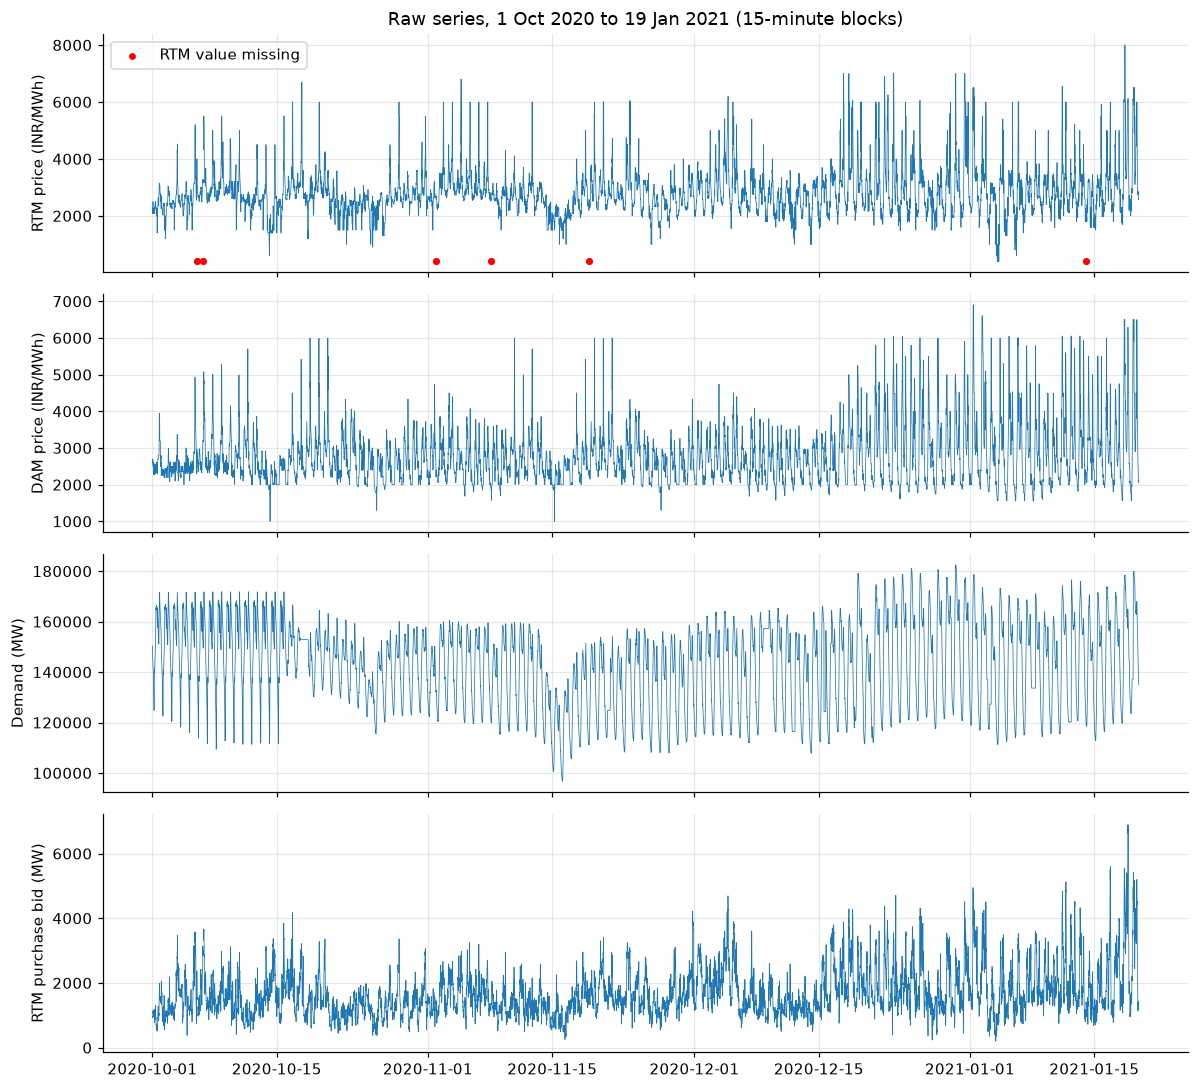

In [5]:
fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
for ax, col, label in zip(
    axes,
    ["rtm_price", "dam_price", "demand", "rtm_purchase_bid"],
    ["RTM price (INR/MWh)", "DAM price (INR/MWh)", "Demand (MW)", "RTM purchase bid (MW)"],
    strict=True,
):
    ax.plot(clean["timestamp"], clean[col], lw=0.5)
    ax.set_ylabel(label)
gone = clean[clean["rtm_missing"]]
axes[0].scatter(
    gone["timestamp"],
    [clean["rtm_price"].min()] * len(gone),
    color="red",
    s=12,
    label="RTM value missing",
    zorder=3,
)
axes[0].legend(loc="upper left")
axes[0].set_title("Raw series, 1 Oct 2020 to 19 Jan 2021 (15-minute blocks)")
fig.tight_layout()
fig.savefig(FIG / "01_raw_series.png")

Prices swing more in late December and January than in October and November. In the first two weeks demand looks too regular:
every day peaks at almost the same level. I come back to that below.

RTM skew 1.621 | DAM skew 1.655


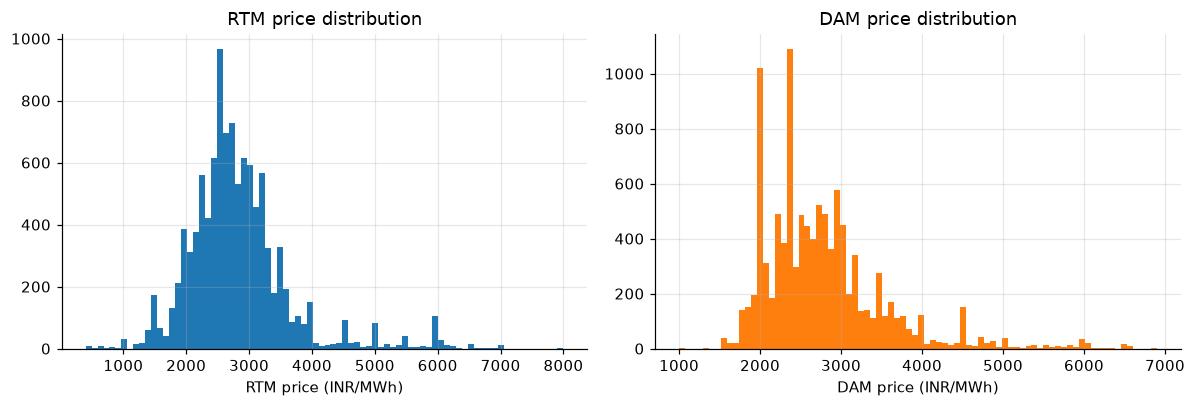

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(clean["rtm_price"].dropna(), bins=80)
axes[0].set_xlabel("RTM price (INR/MWh)")
axes[0].set_title("RTM price distribution")
axes[1].hist(clean["dam_price"], bins=80, color="tab:orange")
axes[1].set_xlabel("DAM price (INR/MWh)")
axes[1].set_title("DAM price distribution")
fig.tight_layout()
fig.savefig(FIG / "01_price_distributions.png")
print("RTM skew", report["rtm_price_skew"], "| DAM skew", round(clean["dam_price"].skew(), 3))

Both price series have a long right tail: a few very high prices and many ordinary ones. A plain average and squared error will be pulled by those spikes.

In [7]:
# Do prices repeat from one block to the next? (stale values would show up as long runs of equal prices)
runs = (clean["rtm_price"].diff() != 0).cumsum()
longest = clean.groupby(runs)["rtm_price"].transform("size").max()
print(
    "rows equal to the previous row:",
    report["rtm_price_equal_to_previous"],
    "| longest run of equal values:",
    int(longest),
)
# Hour-of-day check: first and last timestamp of one day
day = clean[clean["date"] == "2020-10-01"]
print(day["timestamp"].iloc[0], "->", day["timestamp"].iloc[-1], "| blocks:", len(day))

rows equal to the previous row: 48 | longest run of equal values: 2
2020-10-01 00:00:00+05:30 -> 2020-10-01 23:45:00+05:30 | blocks: 96


No RTM price repeats for more than two blocks in a row, so I see no sign of a stuck price feed.

In [8]:
# Demand: runs of exactly equal values and identical days
stale = pd.DataFrame(report["demand_stale_runs"]).sort_values("length", ascending=False)
print(
    "stale cut-off (blocks):",
    report["demand_stale_min_blocks"],
    "| runs:",
    len(stale),
    "| rows:",
    report["demand_stale_rows"],
)
print(stale.head(8).to_string(index=False))
print("days with an identical demand profile:", report["demand_identical_days"])

stale cut-off (blocks): 4 | runs: 16 | rows: 359
                    start  length    value
2020-10-17T15:15:00+05:30      87 152869.0
2020-12-08T18:30:00+05:30      59 157282.0
2021-01-07T22:30:00+05:30      43 133648.0
2020-12-12T00:30:00+05:30      29 116443.0
2020-11-21T05:45:00+05:30      28 124827.0
2021-01-12T04:00:00+05:30      23 120162.0
2020-12-15T14:00:00+05:30      19 124289.0
2021-01-03T05:45:00+05:30      15 127303.0
days with an identical demand profile: [['2020-12-10', '2020-12-17'], ['2020-12-13', '2020-12-20'], ['2020-12-19', '2020-12-26']]


Demand is the weak column. It has 16 runs of four or more identical values, 359 rows in total, and the longest lasts 87 blocks (about 22 hours,
from 17 October). I chose four blocks as the cut-off from the run lengths in the data: runs of two or three occur 12 times, and the rest are longer.
Three pairs of days also share exactly the same 96 values: 10 and 17 December, 13 and 20 December, 19 and 26 December.

                 max       min
date                          
2020-10-01  171594.0  124768.0
2020-10-02  171628.0  122574.0
2020-10-03  171663.0  120380.0
2020-10-04  171697.0  118187.0
2020-10-05  171731.0  115993.0
2020-10-06  171765.0  113799.0
2020-10-07  171799.0  111605.0
2020-10-08  171833.0  109411.0
2020-10-09  171782.0  112702.0
2020-10-10  171795.0  111879.0
2020-10-11  171802.0  111399.0
2020-10-12  171803.0  111348.0
2020-10-13  171796.0  111832.0
2020-10-14  171799.0  111614.0
2020-10-15  171800.0  111548.0
2020-10-16  166630.0  138486.0


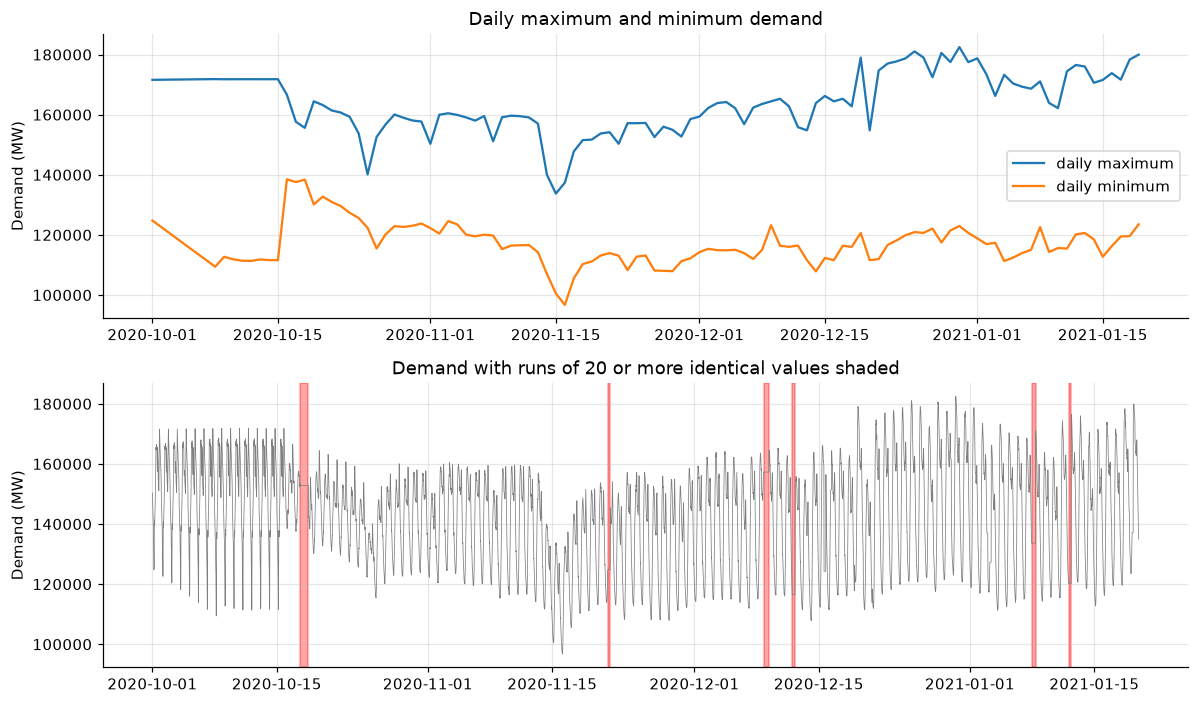

In [9]:
daily = clean.groupby("date")["demand"].agg(["max", "min"])
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5))
axes[0].plot(daily.index, daily["max"], label="daily maximum")
axes[0].plot(daily.index, daily["min"], label="daily minimum")
axes[0].set_ylabel("Demand (MW)")
axes[0].set_title("Daily maximum and minimum demand")
axes[0].legend()
long_runs = stale[stale["length"] >= 20]
axes[1].plot(clean["timestamp"], clean["demand"], lw=0.5, color="tab:gray")
for _, run in long_runs.iterrows():
    start = pd.Timestamp(run["start"])
    axes[1].axvspan(
        start, start + pd.Timedelta(minutes=15 * int(run["length"])), color="red", alpha=0.35
    )
axes[1].set_ylabel("Demand (MW)")
axes[1].set_title("Demand with runs of 20 or more identical values shaded")
fig.tight_layout()
fig.savefig(FIG / "01_demand_artefacts.png")
print(daily.head(16).round(0).to_string())

The first two weeks are the biggest problem. From 1 to 15 October the daily maximum stays between 171594 and 171833 MW. The daily minimum falls steadily
from 124768 to 109411 MW until 8 October, then stays between 111348 and 112702. On 16 October the pattern changes (maximum 166630, minimum 138486).
I cannot tell the cause from the file. Measured demand does not usually look like this, so I treat 1 to 15 October as unreliable.

**What I understand.** Prices are complete apart from six missing half-hours, and the contract passes. Demand is not clean. I keep every row,
add a flag for the doubtful demand rows in step 2.4, and test the models with and without demand features.